# 04 — FdeR final 11-parameter MATLAB model → SciPy

**Forward simulation and likelihood validation only. NO refit, PyBADS or PyVBMC.**

The source is the private original `logPosterior_primary_batchaware_meanwindow.m`: functions `local_model` and `local_sim_mean_window` (21 September 2026). The original v7.3 MAT supplies the **11-parameter posterior**, **growth contexts**, **physical constants**, **doses**, **statistical targets** and **observational window**. The MAT file is intentionally NOT included in this public GitHub/Binder repository.

State order matches MATLAB: `[FdeR, Nar, GFP, Cells, Nar_external]`. Four numerical phases of work are: numerical preequilibration (960 min), measured-growth preinduction, extracellular-dose injection, and measured-growth postinduction. The observable is the **mean of GFP at MATLAB 1-based indices 72:108**, plus the relevant `B1` or `B2` **once**. MATLAB `ode23t/ode23s` is approximated using SciPy `solve_ivp(BDF)`; differing solvers may produce small numerical discrepancies.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'biosensor_pipeline').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print('Project root:', ROOT)


Project root: /workspaces/biosensor-python-pipeline


## 1. Load original frozen configuration, if available

Put the original `Data_pFdeR_final_batchaware_VBMC_20260921_214836.mat` under `private_data/` in a **private Codespace or local workstation**, not in public Binder. Without it, this notebook uses a **fabricated synthetic context** to demonstrate that the code runs, but does not claim correspondence with the historical experiment.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from biosensor_pipeline.models.final_fder import (
    load_final_model, simulate_final_dose_response, final_curve_features,
    construct_rbs_coordinates, logposterior_final_physical)
from biosensor_pipeline.models.synthetic_final_fixture import make_synthetic_final_model
mat_path=ROOT/'private_data/Data_pFdeR_final_batchaware_VBMC_20260921_214836.mat'
real_archive=mat_path.is_file()
model=load_final_model(mat_path) if real_archive else make_synthetic_final_model()
print('Source:', 'ORIGINAL private 2026-09-21 frozen MAT' if real_archive else 'SYNTHETIC fabricated context (not experimental)')
print('11 parameter names:', list(__import__('biosensor_pipeline.models.final_fder', fromlist=['THETA_NAMES']).THETA_NAMES))
print('Observation window [MATLAB 1-based]:',model.obs_window_matlab)
print('Construct q coordinates: R4R3=',construct_rbs_coordinates(model.theta_median,model.qR4_nominal,'R4R3'),
      'R3R3=',construct_rbs_coordinates(model.theta_median,model.qR4_nominal,'R3R3'))

Source: SYNTHETIC fabricated context (not experimental)
11 parameter names: ['etaTF', 'kG_R3', 'kdNar_shared', 'beta', 'n_nar', 'KI_TF_rel', 'gamma_TF', 'rho0_TF', 'B1', 'B2', 'cK2']
Observation window [MATLAB 1-based]: (72, 108)
Construct q coordinates: R4R3= (0.0336076817558299, 1.0) R3R3= (0.6011263749040582, 1.0)


## 2. Simulate contexts and RBS interventions (MATLAB experiment semantics)

- `E1`: R4R3 and R3R3, with common background B1.
- `E2`: R4R3 and R4R4, with common background B2 and `kdNar_shared × cK2`.
- `gamma_TF` changes the effective TF coordinate for R3R3; it is **not** a simple raw qTF=1 in the frozen likelihood.

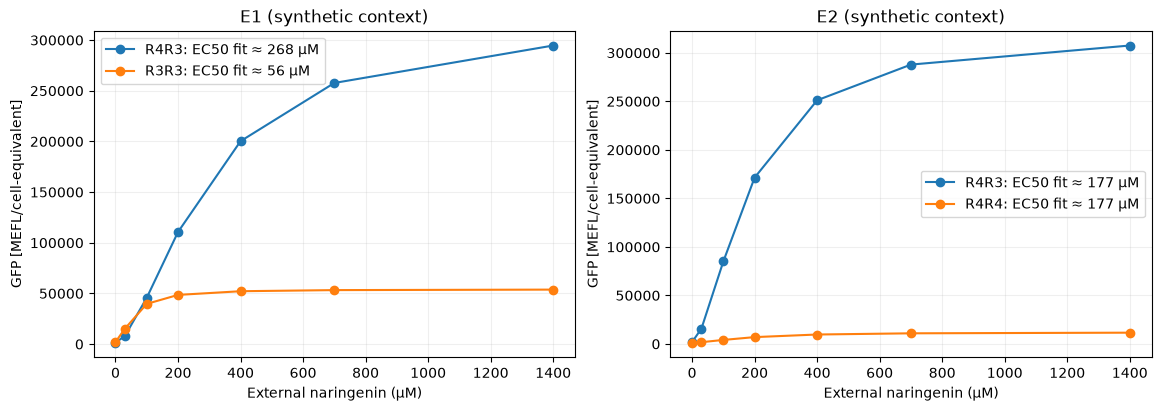

('E1', 'R4R3', 1416.945177589403, 293223.19993684976, 267.6676676676677)
('E1', 'R3R3', 1987.4110313205406, 51765.98342738658, 56.05605605605605)
('E2', 'R4R3', 1905.4247625901194, 305595.3659846274, 176.57657657657657)
('E2', 'R4R4', 1311.7524432654789, 10270.351971707201, 176.57657657657657)


In [3]:
fig,axs=plt.subplots(1,2,figsize=(11.5,4),layout='constrained')
summary=[]
for ax,(exp,constructs) in zip(axs,[('E1',('R4R3','R3R3')),('E2',('R4R3','R4R4'))]):
    for construct in constructs:
        doses,y=simulate_final_dose_response(model,experiment=exp,construct=construct)
        stats=final_curve_features(doses,y)
        summary.append((exp,construct,stats['Leakiness'],stats['DynamicRange'],stats['EC50']))
        ax.plot(doses,y,'o-',label=f'{construct}: EC50 fit ≈ {stats["EC50"]:.0f} µM')
    ax.set(title=exp+' (archived context)' if real_archive else exp+' (synthetic context)',
           xlabel='External naringenin (µM)',ylabel='GFP [MEFL/cell-equivalent]')
    ax.grid(alpha=.2);ax.legend()
plt.show()
for row in summary:print(row)

## 3. Exact archived likelihood structure: 6D + 3D

The archived MATLAB code uses **correlated Gaussian blocks**, not the older diagonal five-feature likelihood. The physical-coordinate uniform prior contributes a Jacobian in transformed VBMC coordinates. A matching log posterior is a stringent numerical check, but **we do not run a new inference**.

In [4]:
if real_archive:
    lp=logposterior_final_physical(model)
    print('Python posterior-median logp:',lp)
    print('Frozen MATLAB logp:',model.reference_logpost_median)
    print('Absolute numerical discrepancy:',abs(lp-model.reference_logpost_median))
else:
    print('Skipped logp comparison: synthetic fixture has no frozen experimental Gaussian targets.')

Skipped logp comparison: synthetic fixture has no frozen experimental Gaussian targets.


## 4. Full private validation against original MATLAB (outside this notebook)

With the original MAT securely available, run:

```bash
python -m scripts.validate_final_fder \\
  --mat private_data/Data_pFdeR_final_batchaware_VBMC_20260921_214836.mat \\
  --out outputs/private_parity --with-seed
```

The script compares **Exp1 R4R3/R3R3** and **Exp2 R4R3/R4R4**, including the likelihood. An independent reference run on 31 October 2026 compared 26 archived summaries (initial seed and posterior median) with a maximum relative feature difference **6.68×10⁻⁶** and a maximum absolute log-posterior discrepancy **4.96×10⁻⁴**. These numerical errors are small, but this does not establish bitwise equivalence or the correctness of a future new posterior fit.